# Predicting Sales Prices

 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


## Import libraries and data

In [14]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Global variables
RANDOM_STATE = 42

In [15]:
# Read in the data set
data = pd.read_csv("ames.csv")

## Pre-process the data and clean, where needed

In [16]:
# Clean and pre-process the data if neccessary
display(data.info())
display(data.describe())
display(data.head(10))
display(data.columns)
dup_count = data.duplicated().sum()
print(f"Number of duplicated rows: {dup_count}")

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Year_Built      2930 non-null   int64
 1   Year_Remod_Add  2930 non-null   int64
 2   Total_Bsmt_SF   2930 non-null   int64
 3   First_Flr_SF    2930 non-null   int64
 4   Second_Flr_SF   2930 non-null   int64
 5   Gr_Liv_Area     2930 non-null   int64
 6   Full_Bath       2930 non-null   int64
 7   Half_Bath       2930 non-null   int64
 8   Bedroom_AbvGr   2930 non-null   int64
 9   Kitchen_AbvGr   2930 non-null   int64
 10  TotRms_AbvGrd   2930 non-null   int64
 11  Fireplaces      2930 non-null   int64
 12  Garage_Area     2930 non-null   int64
 13  Sale_Price      2930 non-null   int64
dtypes: int64(14)
memory usage: 320.6 KB


None

,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
count,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1971.356314,1984.266553,1051.255631,1159.557679,335.455973,1499.690444,1.566553,0.379522,2.854266,1.044369,6.443003,0.599317,472.658362,180796.060068
std,30.245361,20.860286,440.968018,391.890885,428.395715,505.508887,0.552941,0.502629,0.827731,0.214076,1.572964,0.647921,215.187196,79886.692357
min,1872.000000,1950.000000,0.000000,334.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,12789.000000
25%,1954.000000,1965.000000,793.000000,876.250000,0.000000,1126.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,320.000000,129500.000000
50%,1973.000000,1993.000000,990.000000,1084.000000,0.000000,1442.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,480.000000,160000.000000
75%,2001.000000,2004.000000,1301.500000,1384.000000,703.750000,1742.750000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,576.000000,213500.000000
max,2010.000000,2010.000000,6110.000000,5095.000000,2065.000000,5642.000000,4.000000,2.000000,8.000000,3.000000,15.000000,4.000000,1488.000000,755000.000000


,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
0,1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1,1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
2,1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
3,1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
4,1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900
5,1998,1998,926,926,678,1604,2,1,3,1,7,1,470,195500
6,2001,2001,1338,1338,0,1338,2,0,2,1,6,0,582,213500
7,1992,1992,1280,1280,0,1280,2,0,2,1,5,0,506,191500
8,1995,1996,1595,1616,0,1616,2,0,2,1,5,1,608,236500
9,1999,1999,994,1028,776,1804,2,1,3,1,7,1,442,189000


Index(['Year_Built', 'Year_Remod_Add', 'Total_Bsmt_SF', 'First_Flr_SF',
       'Second_Flr_SF', 'Gr_Liv_Area', 'Full_Bath', 'Half_Bath',
       'Bedroom_AbvGr', 'Kitchen_AbvGr', 'TotRms_AbvGrd', 'Fireplaces',
       'Garage_Area', 'Sale_Price'],
      dtype='str')

Number of duplicated rows: 7


In [17]:
# Drop duplicated rows
data = data.drop_duplicates()
display(data.duplicated().sum())
# Check duplicates have been removed 
dup_count = data.duplicated().sum()
print(f"Number of duplicated rows: {dup_count}")

np.int64(0)

Number of duplicated rows: 0


## Commentary
All data fields contained in the ames.csv are in numerical format, specifically int64. This makes sense given what each data field represents - i.e. the square footage of a room and the year built.

The output above shows that there are no missing data points in any of the imported data fields. However, there are 7 duplicated rows which have been removed from the dataframe.

## Explore the data and visualise

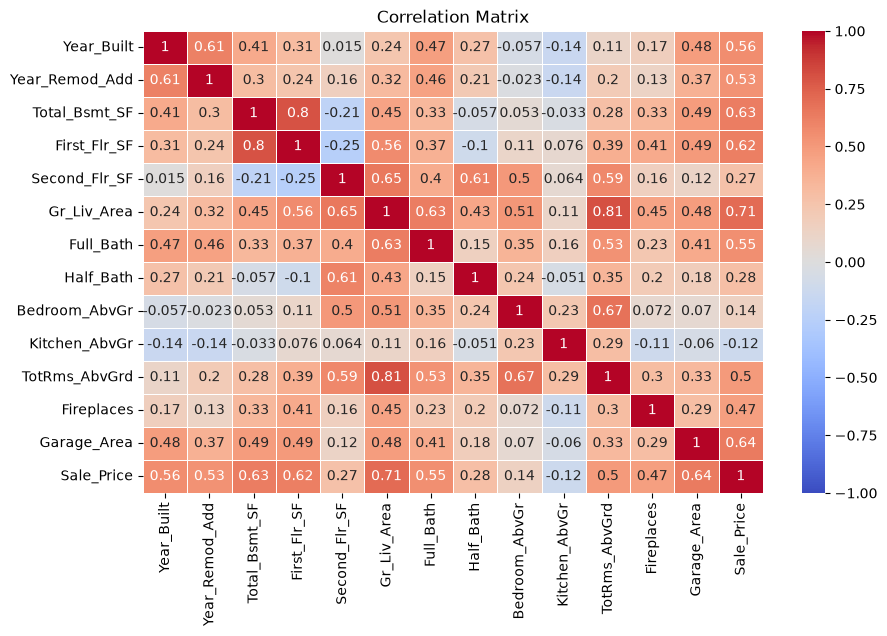

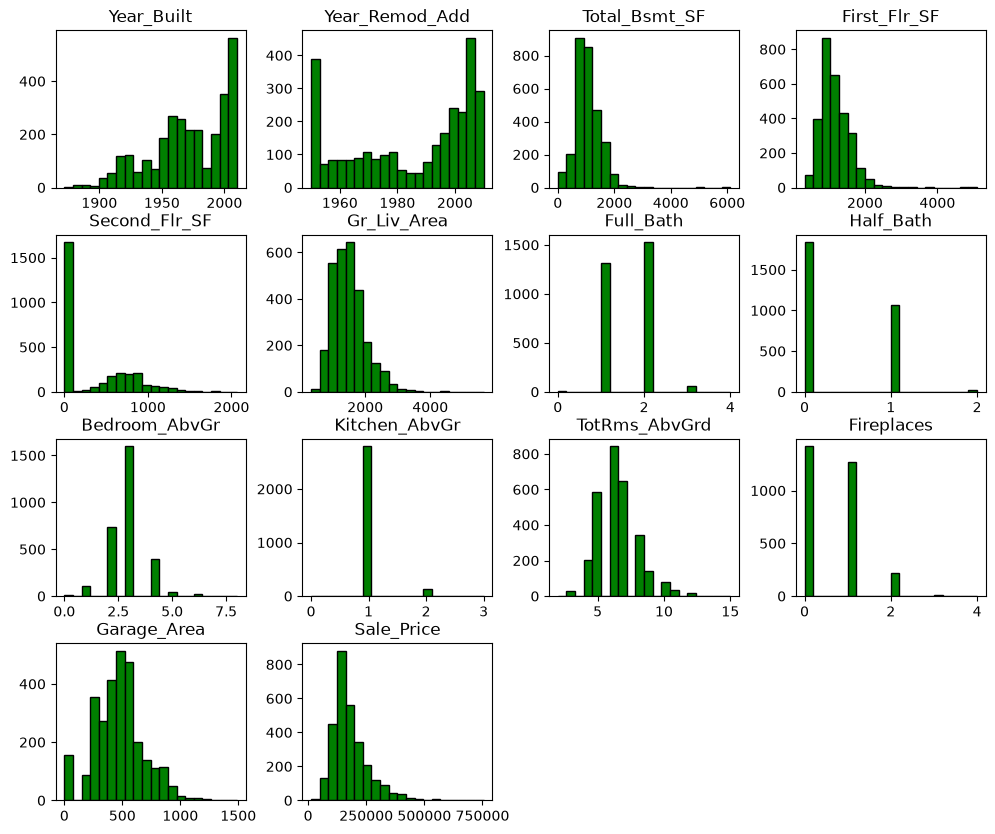

In [ ]:
# Explore the data with visualisations such as histograms and correlation matrices

# Correlation heatmap 
corr_matrix = data.corr()

# Draw the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)

plt.title("Correlation Matrix")
plt.show()

# Histograms
data.hist(figsize=(12, 10), bins=20, edgecolor="black",
          color="green",
          grid=False)
plt.tight_layout
plt.show()


## Commentary
The correlation matrix above highlights which explanatory (X or feature) variables are most strongly associated with higher house prices in Ames between 2006 and 2010. 

The above-grade ground living area shows the strongest positive linear correlation with house prices, with a correlation of 0.71, followed closely by the total garage area (0.64).

The histograms above show each variable's distribution, with many showing noticeable right skweness.

Additionally, no scaling has been applied to the explanatory (X or feature) variables (such as standardisation or normalisation) to 'equalise' the ranges, as this is not part of the task's requirement. 

## Regression model set up

In [19]:
# Split the independent variables from the dependent variable
X = data[['Garage_Area','Gr_Liv_Area']]
y = data['Sale_Price']

print(X)

      Garage_Area  Gr_Liv_Area
0             528         1656
1             730          896
2             312         1329
3             522         2110
4             482         1629
...           ...          ...
2925          588         1003
2926          484          902
2927            0          970
2928          418         1389
2929          650         2000

[2923 rows x 2 columns]


In [20]:
# Generate plots to explore the relationships between the independent and dependent variables
# See correlation heatmap above

In [21]:
# Create a training and test set with a 75:25 split ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25,  random_state=RANDOM_STATE
    )

print("Training data:",X_train.shape, y_train.shape)
print("Test data:",X_test.shape, y_test.shape)

Training data: (2192, 2) (2192,)
Test data: (731, 2) (731,)


In [22]:
# Build a multiple linear regression model using 'Gr_Liv_Area' and 'Garage_Area'
# Create regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Print the trained model's intercept and coefficients
print('Coefficients: \n', model.coef_[0], model.coef_[1])
print('Intercept: \n', model.intercept_)

Coefficients: 
 145.8993450795449 80.37533010977096
Intercept: 
 -9648.137928314827


In [23]:
# Generate predictions for the test set
y_pred = model.predict(X_test)
print(y_pred)

y_pred_train = model.predict(X_train)

[301217.97782497 250768.40857923  77157.21859024 196071.36320346
 178402.33341978 190834.49076156 144637.92335344 269341.34782697
 156999.03097268 399613.95585902 299438.61267145 334592.86798755
  82944.24235814 126766.44124639 171574.05454651 165268.12589048
 116352.57857504 165112.54322391 102690.55473991 116690.71349415
 231202.15388167 204416.13926658 212726.52165765 166668.5456035
 168016.62957112 195025.29467534 143180.6525672  233071.75654374
 168981.13353244 180881.91000132 247742.0663818  233784.56005147
 162979.12183741 228842.39820099 259810.72264506  97828.70860055
 204115.66763467 115737.37704293 140580.483181   170116.84337925
 175903.86714716 243115.28709735 183155.05235951 305775.78776535
 182886.06564143 124239.87577006  78121.72255156 145099.14564557
 118009.98597327 201550.42849139 209236.16450481 245187.46132077
 239360.45855426 119983.54784132 213350.92955935  61447.49554933
 185645.02454735 215567.45932026 152445.55750317 166936.76041778
 144049.87026428 222324.09

In [24]:
# Evaluate the model's performance by computing the mean squared error (MSE) or root mean squared error (RMSE) on the test set using sklearn.metrics.
# Calculate the mean sq error (MSE)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Mean Squared Error (MSE): 2571509687.59
Root Mean Squared Error (RMSE): 50710.06


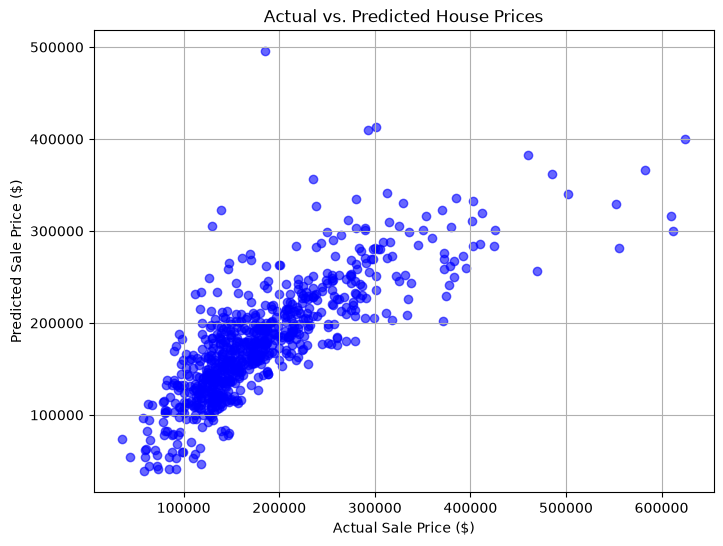

In [25]:
# Generate an error plot to visualise the differences between the predicted and actual values in the test set.
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color="blue", label="Predictions")

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Actual vs. Predicted House Prices")
plt.grid(True)
plt.show()

In [26]:
# Print the coefficients and interpret them within the context of the median value prediction.
print("Coefficients:", model.coef_)
feature = data[['Garage_Area','Gr_Liv_Area']]

for feature, coef in zip(X.columns, model.coef_):
    print(f"{feature} Coefficient: ${coef:.2f}")

# Other key metrics
print(f"\nRoot Mean Squared Error (RMSE): {rmse:.2f}")

# R squared score
print ("R2 Score:", round(model.score(X_test, y_test), 4))

Coefficients: [145.89934508  80.37533011]
Garage_Area Coefficient: $145.90
Gr_Liv_Area Coefficient: $80.38

Root Mean Squared Error (RMSE): 50710.06
R2 Score: 0.6209


## Summarise findings

### Model accuracy and fit
The model achieved a Root Mean Squared Error, which is a measure of accuracy, of $50,710. This tells us that, on average, the model's house price predictions deviate from the actual observed sale price by approximately $50,710. Relative to the average house price (approximately $180,000) this represents an average error rate of ~28%.

Additionally, the model achieved an R-squared value of 0.62, meaning that 62% of the variance in house prices is explained by the regression model (specifically, garage area and above-grade living area combined). 

### Interpreting the coefficients
To predict a house price in Ames during 2006-2010, the model uses the following linear equation:

Predicted sale price = -$9,648.14 + $145.90(garage_area) + $80.38(gr_liv_area)

Interpretation:
1) Holding above-grade living area fixed, each additional square foot of garage space increases the predicted house price by $145.90.
2) Holding garage area fixed, each additional square foot of above-grade living space increases the predicted house price by $80.38.
3) The intercept: if both garage area and living area were 0 sqf, the predicted house price is approximately -$9,648. In practice the data shows that this isn't an observed outcome and is therefore considered a mathematical concept.


Rationale:

Even though above-grade living space (gr_liv_area) has a higher single correlation with house prices than garage area (garage_area), recall that the correlation figure for the former is 0.71 and 0.64 for the latter, multiple regression measures the marginal impact while holding other variables fixed. To put this into perspective, adding 100 sq ft to a garage is a large upgrade relative to adding 100 sq ft to the living space, as adding this extra space could mean space for an extra car in the garage, yet doesn't turn the dial on living space, which is already large in comparison. 

